# Actividad Simulación Monte Carlo
## Edilberto  Antonio Gómez García

### Problema común



### 1 Ley fuerte de los grandes números

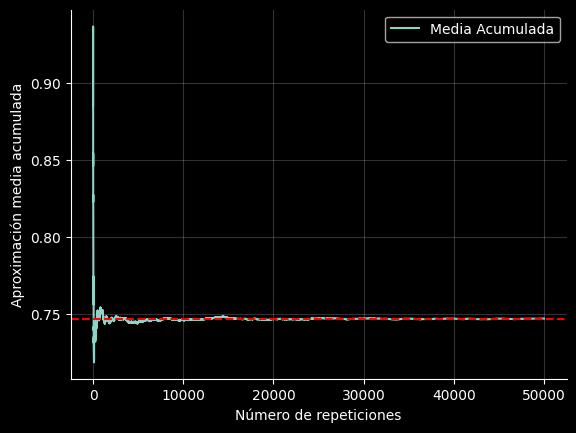

In [31]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
plt.style.use('dark_background')

n = 50000

def monte_carlo_integral(n):
    U = stats.uniform.rvs(loc=0, scale=1, size=n)
    Y = np.exp(-U**2)
    return Y

media_acumulada = monte_carlo_integral(n).cumsum() / np.arange(1, n + 1)
media_acumulada

I_ref = 0.7468241328

plt.plot(media_acumulada, label='Media Acumulada')
plt.axhline(y=I_ref, color='r', linestyle='--')
plt.xlabel('Número de repeticiones')
plt.ylabel('Aproximación media acumulada')
plt.legend()
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

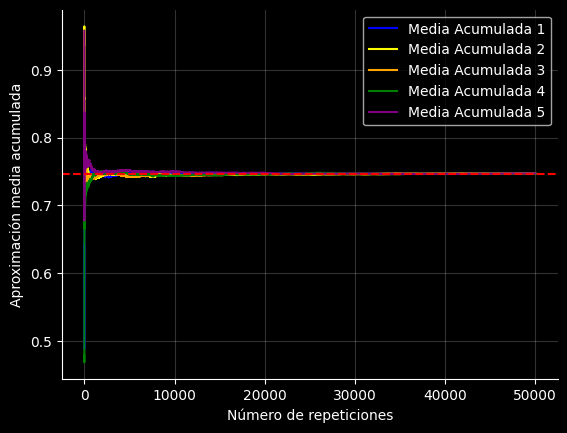

In [32]:
media_acumulada_1 = monte_carlo_integral(n).cumsum() / np.arange(1, n + 1)
media_acumulada_2 = monte_carlo_integral(n).cumsum() / np.arange(1, n + 1)
media_acumulada_3 = monte_carlo_integral(n).cumsum() / np.arange(1, n + 1)
media_acumulada_4 = monte_carlo_integral(n).cumsum() / np.arange(1, n + 1)
media_acumulada_5 = monte_carlo_integral(n).cumsum() / np.arange(1, n + 1)

I_ref = 0.7468241328

plt.plot(media_acumulada_1, label='Media Acumulada 1', color='blue')
plt.plot(media_acumulada_2, label='Media Acumulada 2',  color='yellow')
plt.plot(media_acumulada_3, label='Media Acumulada 3',  color='orange')
plt.plot(media_acumulada_4, label='Media Acumulada 4',  color='green')
plt.plot(media_acumulada_5, label='Media Acumulada 5',  color='purple')
plt.axhline(y=I_ref, color='r', linestyle='--')
plt.xlabel('Número de repeticiones')
plt.ylabel('Aproximación media acumulada')
plt.legend()
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

No necesariamente el error tiene que disminuir paso con paso, ya que como se generan números aleatorios, puede que el siguiente paso se genere un número alto, ocasionando que la media, se mueva un poco del valor real.

La evidencia que se ofrece es que mientras más grande el valor de n, es decir, mientras más simulaciones, más nos acercamos al valor real.

### 2 Ley debil de los grandes números

Tabla de probabilidades estimadas q_n(e):
      e = 0.01  e = 0.02  e = 0.05
n                                 
100      0.593     0.309     0.011
500      0.269     0.028     0.000
1000     0.124     0.000     0.000
5000     0.001     0.000     0.000


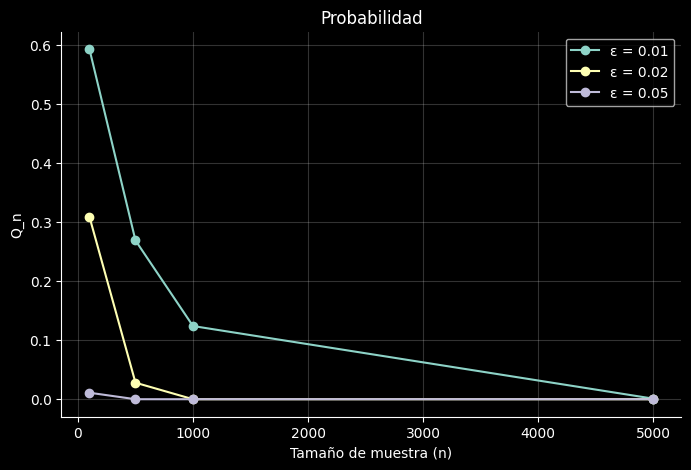

In [33]:
n_valores = [100, 500, 1000, 5000]
epsilon_valores = [0.01, 0.02, 0.05]
R = 1000

resultados = {eps: [] for eps in epsilon_valores}

for n in n_valores:

    U = stats.uniform.rvs(loc=0, scale=1, size=(R, n))
    Y = np.exp(-U**2)

    I_gorro = Y.mean(axis=1)

    error = np.abs(I_gorro - I_ref)

    for eps in epsilon_valores:
        probabilidad = np.mean(error > eps)
        resultados[eps].append(probabilidad)

df_resultados = pd.DataFrame(resultados, index=n_valores)
df_resultados.index.name = 'n'
df_resultados.columns = [f'e = {eps}' for eps in epsilon_valores]

print("Tabla de probabilidades estimadas q_n(e):")
print(df_resultados)

plt.figure(figsize=(8, 5))
for eps in epsilon_valores:
    plt.plot(n_valores, resultados[eps], marker='o', label=f'ε = {eps}')

plt.title('Probabilidad')
plt.xlabel('Tamaño de muestra (n)')
plt.ylabel('Q_n')
plt.legend()
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

Notamos que n influye a decaer la probabilidad del error entre el valor calculado y el valor real sea menor que los epsilon, por lo tanto, el se acerca más rápidamente al valor real $I_{ref}$

La diferencia entre este y el anterior, es que, en el primero si la suma acumulada mientras más grande n más se acerca al valor real y este segundo es que mide la probabilidad de obtener una estimación mayor a un valor de error esperado.

### 3 Teorema del limite central

Varianza (sigma^2) = 0.040398
Desviación estándar (sigma) = 0.200992



/tmp/ipykernel_1444/1981509226.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


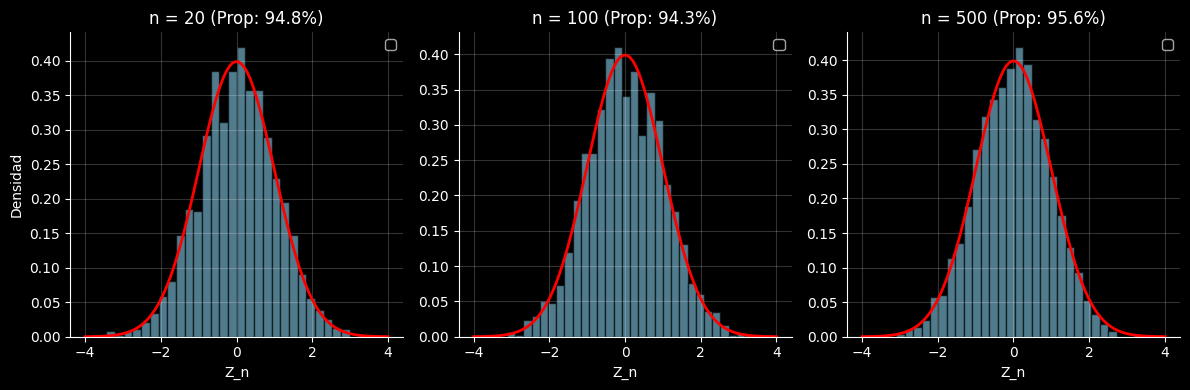

Para n=20, proporción en [-1.96, 1.96]: 94.80%
Para n=100, proporción en [-1.96, 1.96]: 94.35%
Para n=500, proporción en [-1.96, 1.96]: 95.60%


In [42]:
from scipy import integrate

E_Y2, error_estimado = integrate.quad(lambda x: np.exp(-2 * x**2), 0, 1)

sigma_2 = E_Y2 - I_ref**2
sigma = np.sqrt(sigma_2)
print(f"Varianza (sigma^2) = {sigma_2:.6f}")
print(f"Desviación estándar (sigma) = {sigma:.6f}\n")

n_valores = [20, 100, 500]
R = 2000
resultados_prop = {}

plt.figure(figsize=(12, 4))
for i, n in enumerate(n_valores):
    U = stats.uniform.rvs(loc=0, scale=1, size=(R, n))
    Y = np.exp(-U**2)
    I_gorro = Y.mean(axis=1)

    Z_n = np.sqrt(n) * (I_gorro - I_ref) / sigma

    prop = np.mean((Z_n >= -1.96) & (Z_n <= 1.96))
    resultados_prop[n] = prop

    plt.subplot(1, 3, i + 1)
    plt.hist(Z_n, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black')
    x = np.linspace(-4, 4, 100)
    plt.plot(x, stats.norm.pdf(x), 'r-', lw=2)
    plt.title(f'n = {n} (Prop: {prop:.1%})')
    plt.xlabel('Z_n')
    if i == 0: plt.ylabel('Densidad')
    plt.legend()
    plt.grid(alpha=0.2)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

for n, prop in resultados_prop.items():
    print(f"Para n={n}, proporción en [-1.96, 1.96]: {prop:.2%}")

Sabemos que el teorema del limite central, nos dice que independienmente de la distribución de nuestros datos, si la muestra es suficientemente grande al estandaraizar, es decir, $Z$ se aproximará a una distribución normal, con media 0 y desviación 1.

Lo que para nuestros intervalos de confianza, sabemos que en esta distribución normal, entre los valores $(-1.96, 1.96)$, estará alrededor del 95% de nuestros datos, por lo tanto podemos confirmar que alrededor del 95% de los datos que simulamos o estimamos para $I$ están a no más de $\pm 1.96 \frac{\sigma}{\sqrt{n}}$ de distancia del valor real.

### 4 ¿Cuantas simulaciones realizar?

In [44]:
epsilons = [0.02, 0.01, 0.005]
R = 300

n0 = 500
U0 = stats.uniform.rvs(loc=0, scale=1, size=n0)
Y0 = np.exp(-U0**2)
S0 = np.std(Y0, ddof=1)

print(f"Desviación estándar de la muestra piloto (S0): {S0:.6f}\n")

for eps in epsilons:

    n = 30
    while True:
        t_val = stats.t.ppf(0.975, df=n - 1)
        if t_val * S0 / np.sqrt(n) <= eps:
            break
        n += 1

    cobertura = 0
    cumple_Hn = 0
    cumple_error = 0

    for _ in range(R):
        U = stats.uniform.rvs(loc=0, scale=1, size=n)
        Y = np.exp(-U**2)
        I_gorro = np.mean(Y)
        Sn = np.std(Y, ddof=1)

        t_val_n = stats.t.ppf(0.975, df = n - 1)
        Hn = t_val_n * Sn / np.sqrt(n)
        error_abs = np.abs(I_gorro - I_ref)

        if (I_gorro - Hn) <= I_ref <= (I_gorro + Hn):
            cobertura += 1
        if Hn <= eps:
            cumple_Hn += 1
        if error_abs <= eps:
            cumple_error += 1

    print(f"Tolerancia (ε): {eps} | n planificado: {n}")
    print(f" (a) Proporción que contiene I_ref: {cobertura / R:.1%}")
    print(f" (b) Proporción con H_n <= e:       {cumple_Hn / R:.1%}")
    print(f" (c) Proporción con Error <= e:     {cumple_error / R:.1%}\n")

Desviación estándar de la muestra piloto (S0): 0.206347

Tolerancia (ε): 0.02 | n planificado: 412
 (a) Proporción que contiene I_ref: 96.0%
 (b) Proporción con H_n <= e:       90.0%
 (c) Proporción con Error <= e:     96.7%

Tolerancia (ε): 0.01 | n planificado: 1639
 (a) Proporción que contiene I_ref: 93.3%
 (b) Proporción con H_n <= e:       99.7%
 (c) Proporción con Error <= e:     93.3%

Tolerancia (ε): 0.005 | n planificado: 6546
 (a) Proporción que contiene I_ref: 93.0%
 (b) Proporción con H_n <= e:       100.0%
 (c) Proporción con Error <= e:     93.3%



Se requiere saber $\sigma^2$, ya que al principio, sin datos simulados la desconocemos, y como la necesitamos para calcular el semiancho $H_n$ pues necesitamos un valor/estimación inicial de $S_0$, por lo tanto una muestra piloto nos ayuda en eso.

Notamos que aproximadamente n se cuadriplica, es decir, se multiplicó por 4, ya que vemos que cuando calculamos que el valor t, multiplicado por $S_0$ y dividido entre la raiz de n, tiene que ser menor que epsilon, vemos que sigue más o menos un valor de proporcionalidad n con episilon de $1/\epsilon^2$ por lo que al dividir entre 2 a epsilon sale el factor de aproximadamente 4.

El tamaño planificado no garantiza el semiancho ni el error debido a que $S_n$ sigue siendo una variable aleatoria, por lo que dependerá de la muestra que le toque, y eso podrá ocasionar que su valor hará que se modifique al semiancho y el error.

Debido a que estos miden la 3 probabilidades diferentes, el primero es el intervalo de confianza y depende del cuantil $t_{0.975}$, el segundo depende de la varianza de la muestra y el tercero verá que tan alejados se encuentran del punto central.

### 5 Otro caso

In [49]:
epsilon = 0.01
p_teo = np.exp(-3)
print(f"Valor teórico p = {p_teo:.6f}")

n0 = 500
T0 = stats.expon.rvs(scale=1, size=n0)
Y0 = (T0 > 3).astype(int)
S0 = np.std(Y0, ddof=1)

print(f"Desviación estándar de la muestra piloto: {S0:.6f}")
n = 30
while True:
    t_val = stats.t.ppf(0.975, n - 1)
    if t_val * S0 / np.sqrt(n) <= epsilon:
        break
    n += 1

print(f"Tamaño de muestra planificado (n): {n}")

T_final = stats.expon.rvs(scale=1, size=n)
Y_final = (T_final > 3).astype(int)

p_gorro = np.mean(Y_final)
Sn = np.std(Y_final, ddof=1)
t_val_n = stats.t.ppf(0.975, df=n - 1)
semiancho = t_val_n * Sn / np.sqrt(n)
error_abs = np.abs(p_gorro - p_teo)

print(f"\nEstimación (p_gorro):  {p_gorro:.6f}")
print(f"Semiancho: {semiancho:.6f} (<= {epsilon})")
print(f"Error absoluto:      {error_abs:.6f}")

Valor teórico p = 0.049787
Desviación estándar de la muestra piloto: 0.265264
Tamaño de muestra planificado (n): 2706

Estimación (p_gorro):  0.045824
Semiancho: 0.007884 (<= 0.01)
Error absoluto:      0.003963


El tamaño de muestra $n$ cambia porque la varianza del experimento es distinta. Al mantener fijos el margen de error ($\epsilon = 0.01$) y el cuantil de confianza ($t_{0.975}$), el tamaño $n$ pasa a depender de la desviación de los datos. Dado que la variable indicadora tiene una varianza diferente a la del estimador de la integral, el tamaño de muestra debe ajustarse para garantizar la misma precisión.